# FEATURE ENGINEERING

Sprint 2 - Step 1

- Input: the cleaned training data from `01_eda.ipynb` (`data_cleaned/train_clean.csv`).
- Goal: turn every column into a number a model can use, and create new features based on our hypotheses.
- Output: `data_cleaned/train_features.csv`.

## Load the cleaned dataset

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

CLEAN_DIR = Path("../data_cleaned")

train_clean_df = pd.read_csv(
    CLEAN_DIR / "train_clean.csv"
)

print("Cleaned training data:", train_clean_df.shape)

Cleaned training data: (26707, 38)


In [2]:
## Checking the data types after loading
train_clean_df.dtypes.value_counts()

str      35
int64     3
Name: count, dtype: int64

### Learning from loading

- All 35 feature columns are loaded as text, because missing answers were saved as "Unknown".
- Models need numbers, so every column has to be converted.
- The ID and the two target columns are already numeric.

## Grouping the columns

In [3]:
## NOT FEATURES
excluded_columns = [
    "respondent_id",
    "h1n1_vaccine",
    "seasonal_vaccine"
]

target_columns = [
    "h1n1_vaccine",
    "seasonal_vaccine"
]

## YES / NO COLUMNS (0 or 1)
binary_columns = [
    "behavioral_antiviral_meds",
    "behavioral_avoidance",
    "behavioral_face_mask",
    "behavioral_wash_hands",
    "behavioral_large_gatherings",
    "behavioral_outside_home",
    "behavioral_touch_face",
    "doctor_recc_h1n1",
    "doctor_recc_seasonal",
    "chronic_med_condition",
    "child_under_6_months",
    "health_worker",
    "health_insurance"
]

## SCALE COLUMNS (numbers with an order)
scale_columns = [
    "h1n1_concern",
    "h1n1_knowledge",
    "opinion_h1n1_vacc_effective",
    "opinion_h1n1_risk",
    "opinion_h1n1_sick_from_vacc",
    "opinion_seas_vacc_effective",
    "opinion_seas_risk",
    "opinion_seas_sick_from_vacc",
    "household_adults",
    "household_children"
]

## CATEGORIES WITH AN ORDER
ordinal_columns = [
    "age_group",
    "education",
    "income_poverty"
]

## CATEGORIES WITHOUT AN ORDER
nominal_columns = [
    "race",
    "sex",
    "marital_status",
    "rent_or_own",
    "employment_status",
    "census_msa",
    "hhs_geo_region",
    "employment_industry",
    "employment_occupation"
]

feature_columns = (
    binary_columns
    + scale_columns
    + ordinal_columns
    + nominal_columns
)

print("Number of feature columns:", len(feature_columns))

Number of feature columns: 35


### Creating a feature copy

In [4]:
features_df = train_clean_df.copy()
features_df.shape

(26707, 38)

## Step 1: Counting skipped questions

- EDA showed that respondents with missing answers have different vaccination rates.
- Before converting anything, we count how many questions each respondent skipped.

In [5]:
features_df["n_unknown"] = (
    features_df[feature_columns]
    .eq("Unknown")
    .sum(axis=1)
)

features_df["n_unknown"].describe()

count    26707.000000
mean         2.275134
std          2.854102
min          0.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         22.000000
Name: n_unknown, dtype: float64

## Step 2: Missing-value flags

- Columns with a lot of missing answers get a 0/1 flag.
- This keeps the information "this person did not answer" after the gaps are filled.
- `doctor_recc_h1n1` and `doctor_recc_seasonal` are missing for the same people, so one flag is enough.

In [6]:
features_df["health_insurance_missing"] = (
    features_df["health_insurance"]
    .eq("Unknown")
    .astype(int)
)

features_df["doctor_recc_missing"] = (
    features_df["doctor_recc_h1n1"]
    .eq("Unknown")
    .astype(int)
)

features_df["income_poverty_missing"] = (
    features_df["income_poverty"]
    .eq("Unknown")
    .astype(int)
)

features_df[
    [
        "health_insurance_missing",
        "doctor_recc_missing",
        "income_poverty_missing"
    ]
].mean().mul(100).round(1)

health_insurance_missing    46.0
doctor_recc_missing          8.1
income_poverty_missing      16.6
dtype: float64

## Step 3: "Don't know" flags for the opinion questions

- In the opinion questions the value 3 means "Don't know", not a middle opinion.
- EDA showed that this group has the lowest vaccination rates for the "sick from vaccine" questions.
- Each opinion question gets a 0/1 "dont_know" flag.

In [7]:
opinion_columns = [
    column
    for column in scale_columns
    if column.startswith("opinion_")
]

for column in opinion_columns:
    features_df[f"{column}_dont_know"] = (
        features_df[column]
        .eq("3")
        .astype(int)
    )

features_df[
    [f"{column}_dont_know" for column in opinion_columns]
].mean().mul(100).round(1)

opinion_h1n1_vacc_effective_dont_know    17.7
opinion_h1n1_risk_dont_know               4.2
opinion_h1n1_sick_from_vacc_dont_know     0.6
opinion_seas_vacc_effective_dont_know     4.6
opinion_seas_risk_dont_know               2.5
opinion_seas_sick_from_vacc_dont_know     0.4
dtype: float64

## Step 4: Converting yes/no and scale columns to numbers

- "Unknown" is turned into a missing value and then filled with the median of the column.
- The missing information is not lost, because it is kept in the flags and in `n_unknown`.

In [8]:
for column in binary_columns + scale_columns:
    numeric_values = pd.to_numeric(
        features_df[column].replace("Unknown", np.nan)
    )

    median_value = numeric_values.median()

    features_df[column] = (
        numeric_values
        .fillna(median_value)
        .astype(int)
    )

features_df[binary_columns + scale_columns].dtypes.value_counts()

int64    23
Name: count, dtype: int64

## Step 5: Encoding ordered categories

- Age, education and income have a natural order, so they become ranks (0, 1, 2, ...).
- "Unknown" education and income are filled with the median rank.

In [9]:
age_order = {
    "18 - 34 Years": 0,
    "35 - 44 Years": 1,
    "45 - 54 Years": 2,
    "55 - 64 Years": 3,
    "65+ Years": 4
}

education_order = {
    "< 12 Years": 0,
    "12 Years": 1,
    "Some College": 2,
    "College Graduate": 3
}

income_order = {
    "Below Poverty": 0,
    "<= $75,000, Above Poverty": 1,
    "> $75,000": 2
}

ordinal_maps = {
    "age_group": age_order,
    "education": education_order,
    "income_poverty": income_order
}

for column, order in ordinal_maps.items():
    ranks = features_df[column].map(order)

    features_df[column] = (
        ranks
        .fillna(ranks.median())
        .astype(int)
    )

features_df[ordinal_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
age_group,26707.0,2.186131,1.457320,0.0,1.0,2.0,4.0,4.0
education,26707.0,1.984049,0.974074,0.0,1.0,2.0,3.0,3.0
income_poverty,26707.0,1.154005,0.576428,0.0,1.0,1.0,2.0,2.0


## Step 6: Creating new features from our hypotheses

| New feature | How it is built | Hypothesis |
| --- | --- | --- |
| `preventive_score` | number of preventive behaviours (0-7) | H4 |
| `h1n1_belief_score` | H1N1 vaccine effective + H1N1 risk (2-10) | H4 |
| `seas_belief_score` | seasonal vaccine effective + seasonal risk (2-10) | H4 |
| `any_doctor_recc` | doctor recommended at least one vaccine | H3 |
| `high_risk_person` | 65+, chronic condition, or health worker | H1, H5 |

In [10]:
behavioral_columns = [
    column
    for column in binary_columns
    if column.startswith("behavioral_")
]

# Number of preventive behaviours
features_df["preventive_score"] = (
    features_df[behavioral_columns]
    .sum(axis=1)
)

# Belief that the vaccine works and that the flu is risky
features_df["h1n1_belief_score"] = (
    features_df["opinion_h1n1_vacc_effective"]
    + features_df["opinion_h1n1_risk"]
)

features_df["seas_belief_score"] = (
    features_df["opinion_seas_vacc_effective"]
    + features_df["opinion_seas_risk"]
)

# Doctor recommended at least one vaccine
features_df["any_doctor_recc"] = (
    features_df[["doctor_recc_h1n1", "doctor_recc_seasonal"]]
    .max(axis=1)
)

# Person belongs to a high-risk or exposed group
features_df["high_risk_person"] = (
    (features_df["age_group"] == age_order["65+ Years"])
    | (features_df["chronic_med_condition"] == 1)
    | (features_df["health_worker"] == 1)
).astype(int)

new_features = [
    "preventive_score",
    "h1n1_belief_score",
    "seas_belief_score",
    "any_doctor_recc",
    "high_risk_person",
    "n_unknown"
]

features_df[new_features].describe().T

,count,mean,std,min,25%,50%,75%,max
preventive_score,26707.0,3.043846,1.599161,0.0,2.0,3.0,4.0,7.0
h1n1_belief_score,26707.0,6.190400,1.815013,2.0,5.0,6.0,7.0,10.0
seas_belief_score,26707.0,6.730857,2.017294,2.0,6.0,6.0,8.0,10.0
any_doctor_recc,26707.0,0.332797,0.471223,0.0,0.0,0.0,1.0,1.0
high_risk_person,26707.0,0.499757,0.500009,0.0,0.0,0.0,1.0,1.0
n_unknown,26707.0,2.275134,2.854102,0.0,1.0,2.0,3.0,22.0


## Step 7: One-hot encoding categories without an order

- Each category becomes its own 0/1 column.
- "Unknown" stays as its own column, so the missing information is kept.

In [11]:
features_df = pd.get_dummies(
    features_df,
    columns=nominal_columns,
    dtype=int
)

print("Shape after one-hot encoding:", features_df.shape)

Shape after one-hot encoding: (26707, 119)


## CHECKING THE NEW FEATURES

### Correlation of the new features with the targets

- The new scores are compared with the strongest single columns from the EDA.

,H1N1,Seasonal
doctor_recc_h1n1,0.394,0.199
h1n1_belief_score,0.373,0.264
opinion_h1n1_risk,0.321,0.216
seas_belief_score,0.269,0.455
opinion_h1n1_vacc_effective,0.267,0.203
opinion_seas_risk,0.256,0.387
any_doctor_recc,0.255,0.338
doctor_recc_seasonal,0.219,0.361
opinion_seas_vacc_effective,0.178,0.359
high_risk_person,0.139,0.294


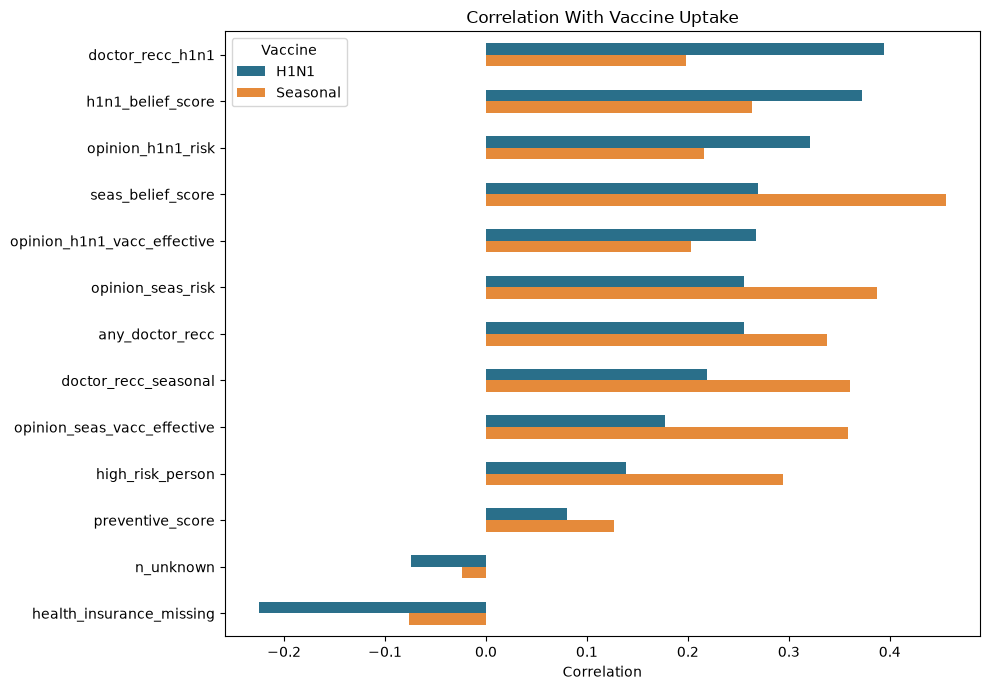

In [12]:
compare_columns = new_features + [
    "doctor_recc_h1n1",
    "doctor_recc_seasonal",
    "opinion_h1n1_vacc_effective",
    "opinion_seas_vacc_effective",
    "opinion_h1n1_risk",
    "opinion_seas_risk",
    "health_insurance_missing"
]

correlations = (
    features_df[compare_columns + target_columns]
    .corr()
    .loc[compare_columns, target_columns]
    .rename(
        columns={
            "h1n1_vaccine": "H1N1",
            "seasonal_vaccine": "Seasonal"
        }
    )
    .sort_values("H1N1", ascending=False)
)

display(correlations.round(3))

ax = correlations.plot(
    kind="barh",
    figsize=(10, 7),
    color=["#2A6F8A", "#E58A3A"]
)

plt.title("Correlation With Vaccine Uptake")
plt.xlabel("Correlation")
plt.ylabel("")
plt.legend(title="Vaccine")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Learning from the correlations

- `h1n1_belief_score` (0.373) is a stronger H1N1 signal than either opinion on its own (0.321 and 0.267).
- `seas_belief_score` (0.455) is the strongest seasonal feature of all, stronger than the seasonal doctor recommendation (0.361).
- `doctor_recc_h1n1` stays the strongest H1N1 feature (0.394).
- `high_risk_person` is useful mostly for the seasonal vaccine (0.294).
- `health_insurance_missing` has a clear negative link with H1N1 (-0.225). Keeping the missing flag was worth it.
- `preventive_score` and `n_unknown` are weak signals.

### Vaccination rate by preventive score

,H1N1,Seasonal
preventive_score,,
0,12.1,29.4
1,16.3,36.6
2,20.5,43.3
3,22.8,49.7
4,22.7,51.2
5,23.1,52.5
6,28.4,53.3
7,33.3,47.4


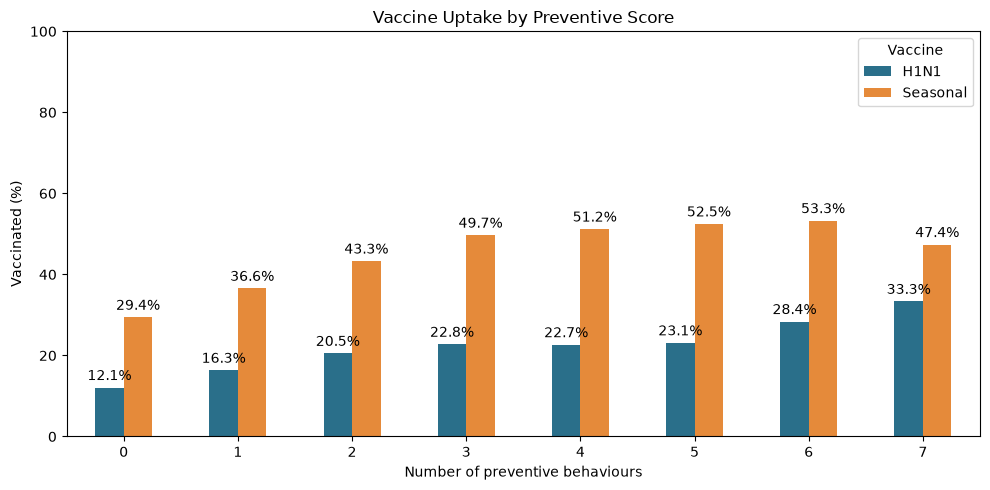

In [13]:
rates = (
    features_df
    .groupby("preventive_score")[target_columns]
    .mean()
    .mul(100)
    .rename(
        columns={
            "h1n1_vaccine": "H1N1",
            "seasonal_vaccine": "Seasonal"
        }
    )
)

display(rates.round(1))

ax = rates.plot(
    kind="bar",
    figsize=(10, 5),
    color=["#2A6F8A", "#E58A3A"]
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.title("Vaccine Uptake by Preventive Score")
plt.xlabel("Number of preventive behaviours")
plt.ylabel("Vaccinated (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title="Vaccine")
plt.tight_layout()
plt.show()

### Learning from the preventive score

- Uptake rises with the number of preventive behaviours (H1N1 12.1% with 0 behaviours → 33.3% with 7).
- The effect is smaller than for beliefs or doctor recommendations, which matches the EDA.

### Final checks

In [14]:
print(
    "Total missing values:",
    features_df.isna().sum().sum()
)

print(
    "Non-numeric columns:",
    features_df.select_dtypes(exclude="number").shape[1]
)

print("Before feature engineering:", train_clean_df.shape)
print("After feature engineering:", features_df.shape)

Total missing values: 0
Non-numeric columns: 0
Before feature engineering: (26707, 38)
After feature engineering: (26707, 119)


### Saving the feature dataset

In [15]:
features_df.to_csv(
    CLEAN_DIR / "train_features.csv",
    index=False
)

print("Saved:", CLEAN_DIR / "train_features.csv")

Saved: ..\data_cleaned\train_features.csv
